# Cross-Validation and K-Fold Cross-Validation

## 1. Training, Validation, and Testing in Machine Learning

In machine learning, data is typically split into three main sets: **training**, **validation**, and **testing**. Each of these sets serves a distinct purpose in the model-building process, allowing us to build models that generalize well to unseen data. Here’s an overview of each phase and its role:

### Training Set

The **training set** is the portion of the data used to train the model. The model learns patterns, relationships, and underlying distributions in this dataset. During the training phase, the model adjusts its parameters (such as weights in a neural network) to minimize the error or loss function with respect to the target variable.

- **Key Goal**: Optimize the model’s performance on this dataset.
- **Model Behavior**: As the model is trained, its error on the training set typically decreases because it is "fitting" to the known data.

### Validation Set

The **validation set** is used to tune the hyperparameters of the model, such as regularization strength, learning rate, kernel width (in kernel methods), or the number of layers in a neural network. The model does not directly train on this data, but instead, it helps to monitor performance and prevent **overfitting**.

- **Key Goal**: Assess the model’s performance on unseen data during the training process to fine-tune hyperparameters and detect overfitting.
- **Model Behavior**: If the model performs well on the training set but poorly on the validation set, this might indicate **overfitting** (the model is too specific to the training data and doesn’t generalize well).
- **Use Case**: Often used in **cross-validation**, where data is split into multiple folds and the model is trained and validated on different subsets of the data.

### Testing Set

The **test set** is used to evaluate the final model after the training and validation phases are complete. It acts as the ultimate measure of the model’s generalization capability, indicating how well the model is expected to perform on real-world, unseen data.

- **Key Goal**: Provide an unbiased evaluation of the final model.
- **Model Behavior**: The test set is only used once, after the model has been fully trained and tuned using the training and validation sets. The error on the test set gives us an estimate of how well the model will perform in practice.

### Why Split Data Into Three Sets?

1. **Training Set**: Used to **train** the model by minimizing the error on known data.
2. **Validation Set**: Used to **validate** model performance and tune hyperparameters during training.
3. **Test Set**: Used to **test** the model’s ability to generalize to unseen data after training is complete.

### Avoiding Overfitting:

- **Overfitting** occurs when the model performs very well on the training data but poorly on new, unseen data. This happens because the model has learned specific details and noise in the training data that don’t generalize.
- **Validation** helps in detecting overfitting by evaluating the model’s performance on unseen data during training. If the training error is much lower than the validation error, the model is likely overfitting.
- By testing the final model on the **test set**, we ensure that the model is not overly complex or biased toward the training/validation data.

<img src="./figures/validation.png" alt="Alt text" width="600" height="400" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;"></p>

## 2. What is Cross-Validation?

Cross-validation is a technique used to assess the generalization performance of a machine learning model by splitting the available data into training and validation sets multiple times. The key idea is to use different subsets of data for training and testing, ensuring the model performs well on unseen data.

### Why Cross-Validation?

When training a model, it’s important to evaluate how well it will perform on data that it hasn't seen before. A single train-test split may not be representative of the model’s performance, especially when the dataset is small or imbalanced. Cross-validation helps to:
- **Reduce overfitting** by ensuring the model generalizes well.
- **Provide a more reliable estimate** of model performance by using different portions of the data for validation.
- **Utilize the entire dataset** for both training and testing.

## K-Fold Cross-Validation

**K-Fold Cross-Validation** is one of the most commonly used cross-validation techniques. In this method, the data is divided into **K** equal-sized subsets or "folds". The model is trained on **K-1** folds and tested on the remaining fold. This process is repeated **K** times, with each fold used once as the validation set.
<img src="./figures/cross_val.png" alt="Alt text" width="600" height="400" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;"></p>

### Steps of K-Fold Cross-Validation:

1. Split the dataset into **K** subsets (folds).
2. For each fold $ i = 1, 2, \dots, K $:
   - Use the $i$-th fold as the validation set.
   - Use the remaining $K-1$ folds to train the model.
   - Calculate the performance metric (e.g., accuracy, mean squared error) for the validation set.
3. Average the performance metrics from all **K** folds to obtain the final model evaluation.

### K-Fold Cross-Validation Formula

Let’s define:
- $ D$ as the entire dataset.
- $D^{(i)} $as the subset (fold) used for validation in the $i$-th fold.
- $f^{(i)}(x)$ as the model trained on the data excluding the $i$-th fold.

The model performance is evaluated using a metric \( MSE \) (mean squared error) over the validation set for each fold:

$$
MSE^{(i)} = \frac{1}{n_i} \sum_{j \in D^{(i)}} \left( y_j - f^{(i)}(x_j) \right)^2
$$

where:
- $n_i$ is the number of data points in the $i$-th validation set.
- $y_j$ is the true value for the $j$-th data point.
- $f^{(i)}(x_j)$ is the predicted value for the $j$-th data point in the $i$-th fold.

The final performance metric is the average of the metrics over all folds:

$$
MSE_{K-\text{fold}} = \frac{1}{K} \sum_{i=1}^{K} MSE^{(i)}
$$

### Example: 5-Fold Cross-Validation

For **5-Fold Cross-Validation**, the dataset is split into 5 parts. The process can be described as follows:
1. Train on folds 1–4, test on fold 5.
2. Train on folds 1–3 and 5, test on fold 4.
3. Train on folds 1–2 and 4–5, test on fold 3.
4. Train on folds 1 and 3–5, test on fold 2.
5. Train on folds 2–5, test on fold 1.

Finally, the average of the test results from all 5 runs is calculated to get the final model evaluation.

## Stratified K-Fold Cross-Validation

When dealing with **classification problems**, especially with imbalanced datasets, it is essential to ensure that each fold contains a similar distribution of classes as the entire dataset. This is achieved using **Stratified K-Fold Cross-Validation**, which maintains the same proportion of class labels across all folds.

### Advantages of K-Fold Cross-Validation:

1. **Efficient Use of Data**: All data points are used for both training and validation, which is especially beneficial when the dataset is small.
2. **Reduced Variance**: By averaging the results over multiple folds, the variance in the performance estimate is reduced, leading to a more robust evaluation.
3. **Balanced Assessment**: Each data point is used for validation exactly once, ensuring a fair assessment of model performance.

### Disadvantages of K-Fold Cross-Validation:

1. **Computational Cost**: Training and evaluating the model multiple times (once for each fold) can be computationally expensive, particularly for large datasets or complex models.
2. **Independence Assumption**: K-Fold Cross-Validation assumes that the data points are independent of each other, which may not hold true for time-series data or data with dependencies.

## Special Cases of K-Fold Cross-Validation

### Leave-One-Out Cross-Validation (LOO-CV)

**Leave-One-Out Cross-Validation (LOO-CV)** is a special case of K-Fold Cross-Validation where $K = n$, where $n$ is the total number of data points. In LOO-CV:
- Each fold contains a single data point.
- The model is trained on $n-1$ points and validated on the remaining point.

The final performance metric is the average over all $n$ single-point folds:

$$
MSE_{LOO} = \frac{1}{n} \sum_{i=1}^{n} \left( y_i - f^{(-i)}(x_i) \right)^2
$$

LOO-CV provides a very thorough evaluation but is computationally expensive for large datasets.

## Conclusion

K-Fold Cross-Validation is a powerful tool for evaluating model performance. By splitting the data into multiple folds, it provides a more reliable estimate of how well a model will generalize to new data. While it is more computationally intensive than a simple train-test split, it helps in reducing the risk of overfitting and underfitting, leading to better model selection and performance evaluation.


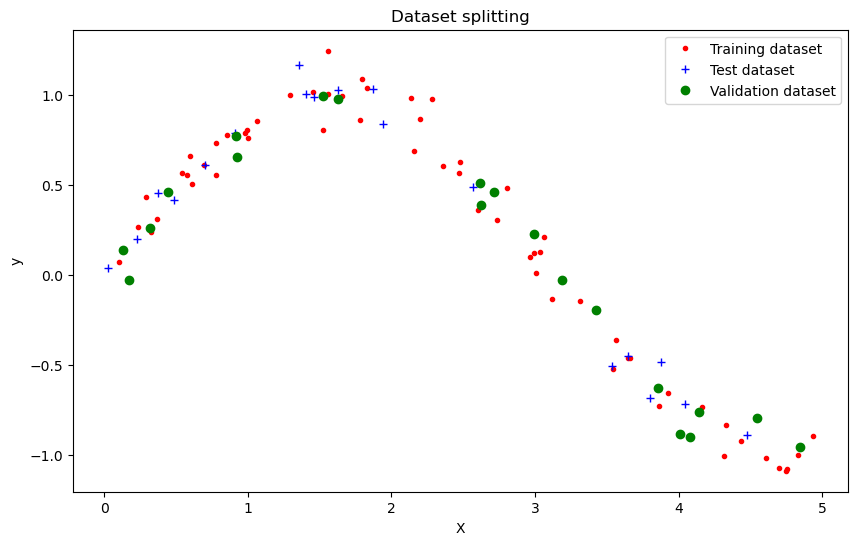

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Define the RBF Kernel function
def rbf_kernel(X1, X2, gamma=0.1):
    """Radial Basis Function (RBF) kernel implementation."""
    K = np.zeros((X1.shape[0], X2.shape[0]))
    for i in range(X1.shape[0]):
        for j in range(X2.shape[0]):
            K[i, j] = np.exp(-gamma * np.linalg.norm(X1[i] - X2[j])**2)
    return K

#Gradient Descent for kernel regression with error tracking
def train_rbf_kernel(X_train, y_train, X_val, y_val, X_test, y_test, gamma=0.1, lr=0.001, epochs=1000):
    """Train a kernel-based model using gradient descent with error tracking."""
    n_samples = X_train.shape[0]
    
    # Initialize dual coefficients (alpha) randomly
    alpha = np.random.randn(n_samples)
    
    # Precompute the kernel matrix for the training data
    K_train = rbf_kernel(X_train, X_train, gamma)
    
    # Lists to track errors
    train_errors = []
    val_errors = []
    test_errors = []
    
    # Gradient Descent loop
    for epoch in range(epochs):
        # Compute gradient
        gradient = np.dot(K_train, alpha) - y_train
        
        # Update alpha using gradient descent
        alpha -= lr * gradient
        
        # Calculate errors for training, validation, and test sets
        train_error = np.mean((np.dot(K_train, alpha) - y_train)**2)
        
        # Kernel matrices for validation and test sets
        K_val = rbf_kernel(X_val, X_train, gamma)
        K_test = rbf_kernel(X_test, X_train, gamma)
        
        # Predictions and errors for validation and test sets
        y_val_pred = np.dot(K_val, alpha)
        y_test_pred = np.dot(K_test, alpha)
        
        val_error = np.mean((y_val_pred - y_val)**2)
        test_error = np.mean((y_test_pred - y_test)**2)
        
        # Append errors to lists
        train_errors.append(train_error)
        val_errors.append(val_error)
        test_errors.append(test_error)
        
        if epoch % 100 == 0:
            print(f"Epoch {epoch}, Training Loss: {train_error:.4f}, Validation Loss: {val_error:.4f}, Test Loss: {test_error:.4f}")
    
    return alpha, train_errors, val_errors, test_errors, y_test_pred

# Generate synthetic nonlinear data
np.random.seed(42)
X = np.sort(5 * np.random.rand(100, 1), axis=0)  # Features
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])  # Nonlinear target with noise

#Split the data into training, validation, and test sets using train_test_split
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)  # 20% validation

plt.figure(figsize=(10, 6))
plt.plot(X_train, y_train, 'r.', label="Training dataset")
plt.plot(X_test, y_test, 'b+', label="Test dataset")
plt.plot(X_val, y_val, 'go', label="Validation dataset")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Dataset splitting")
plt.legend()
plt.show()

Epoch 0, Training Loss: 60.7624, Validation Loss: 62.9464, Test Loss: 59.9787
Epoch 100, Training Loss: 0.4069, Validation Loss: 0.3575, Test Loss: 0.3958
Epoch 200, Training Loss: 0.3143, Validation Loss: 0.2778, Test Loss: 0.3189
Epoch 300, Training Loss: 0.2567, Validation Loss: 0.2370, Test Loss: 0.2732
Epoch 400, Training Loss: 0.2207, Validation Loss: 0.2151, Test Loss: 0.2466
Epoch 500, Training Loss: 0.1980, Validation Loss: 0.2040, Test Loss: 0.2313
Epoch 600, Training Loss: 0.1835, Validation Loss: 0.1991, Test Loss: 0.2228
Epoch 700, Training Loss: 0.1743, Validation Loss: 0.1975, Test Loss: 0.2181
Epoch 800, Training Loss: 0.1682, Validation Loss: 0.1975, Test Loss: 0.2156
Epoch 900, Training Loss: 0.1641, Validation Loss: 0.1983, Test Loss: 0.2143


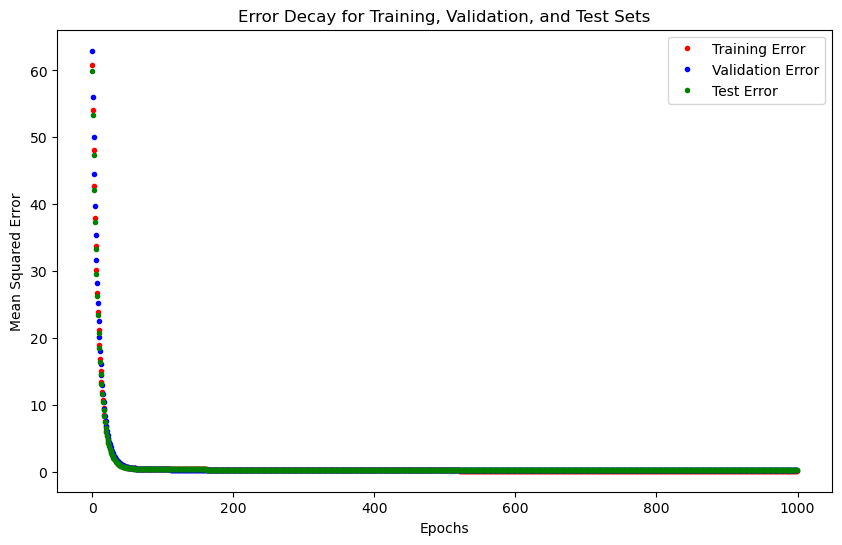

In [2]:
#Train the model with gradient descent
gamma = 0.01  # Kernel hyperparameter
epochs = 1000
alpha, train_errors, val_errors, test_errors, y_test_pred = train_rbf_kernel(X_train, y_train, X_val, y_val, X_test, y_test, gamma, lr=0.001, epochs=epochs)

#Plot training history over epochs
plt.figure(figsize=(10, 6))
plt.plot(range(epochs), train_errors, 'r.', label="Training Error")
plt.plot(range(epochs), val_errors, 'b.', label="Validation Error")
plt.plot(range(epochs), test_errors, 'g.', label="Test Error")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.yscale('log')
plt.title("Error Decay for Training, Validation, and Test Sets")
plt.legend()
plt.show()

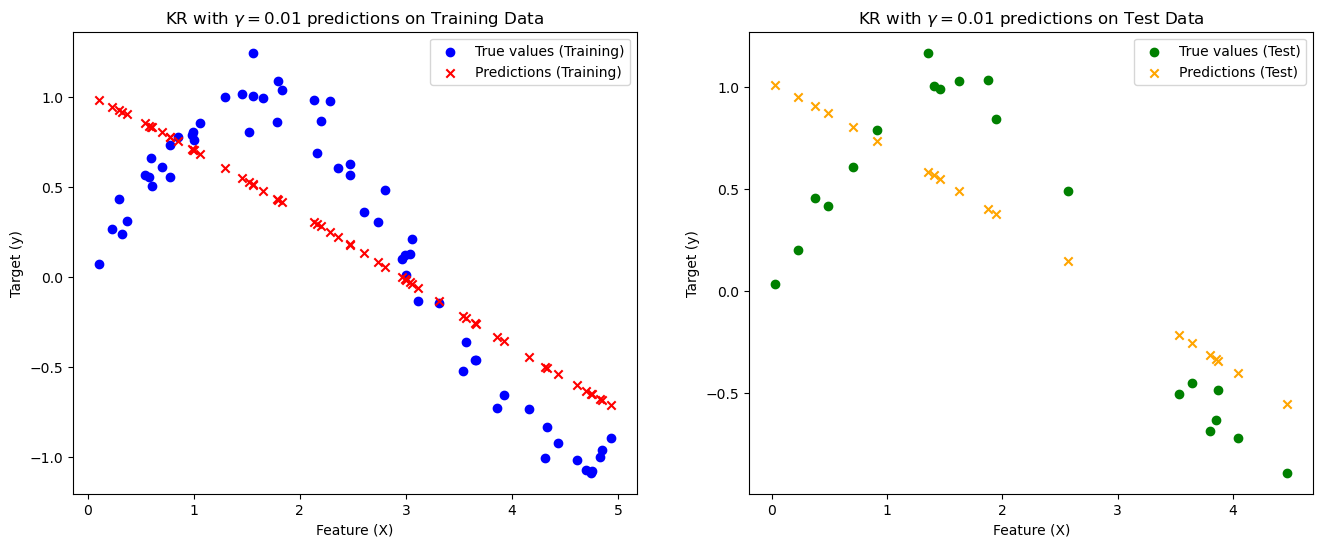

In [3]:
# Final Test Set Predictions for Kernel Regression and Visualizing Performance
# Predictions on training set
K_train = rbf_kernel(X_train, X_train, gamma)
y_train_pred = np.dot(K_train, alpha)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# Plot true values and predictions for training set
ax1.scatter(X_train, y_train, color='blue', label="True values (Training)")
ax1.scatter(X_train, y_train_pred, color='red', label="Predictions (Training)", marker='x')
ax1.set_xlabel("Feature (X)")
ax1.set_ylabel("Target (y)")
ax1.set_title(r"KR with $\gamma=0.01$ predictions on Training Data")
ax1.legend()

# Plot true values and predictions for test set
ax2.scatter(X_test, y_test, color='green', label="True values (Test)")
ax2.scatter(X_test, y_test_pred, color='orange', label="Predictions (Test)", marker='x')
ax2.set_xlabel("Feature (X)")
ax2.set_ylabel("Target (y)")
ax2.set_title(r"KR with $\gamma=0.01$ predictions on Test Data")
ax2.legend()
plt.show()

Epoch 0, Training Loss: 2.0341, Validation Loss: 1.4231, Test Loss: 1.9579
Epoch 100, Training Loss: 1.2561, Validation Loss: 0.9465, Test Loss: 1.3513
Epoch 200, Training Loss: 0.8059, Validation Loss: 0.6587, Test Loss: 0.9682
Epoch 300, Training Loss: 0.5385, Validation Loss: 0.4784, Test Loss: 0.7197
Epoch 400, Training Loss: 0.3748, Validation Loss: 0.3613, Test Loss: 0.5540
Epoch 500, Training Loss: 0.2712, Validation Loss: 0.2825, Test Loss: 0.4400
Epoch 600, Training Loss: 0.2033, Validation Loss: 0.2278, Test Loss: 0.3592
Epoch 700, Training Loss: 0.1572, Validation Loss: 0.1886, Test Loss: 0.3001
Epoch 800, Training Loss: 0.1247, Validation Loss: 0.1599, Test Loss: 0.2557
Epoch 900, Training Loss: 0.1012, Validation Loss: 0.1384, Test Loss: 0.2214
Epoch 1000, Training Loss: 0.0836, Validation Loss: 0.1220, Test Loss: 0.1944
Epoch 1100, Training Loss: 0.0701, Validation Loss: 0.1093, Test Loss: 0.1726
Epoch 1200, Training Loss: 0.0595, Validation Loss: 0.0993, Test Loss: 0.154

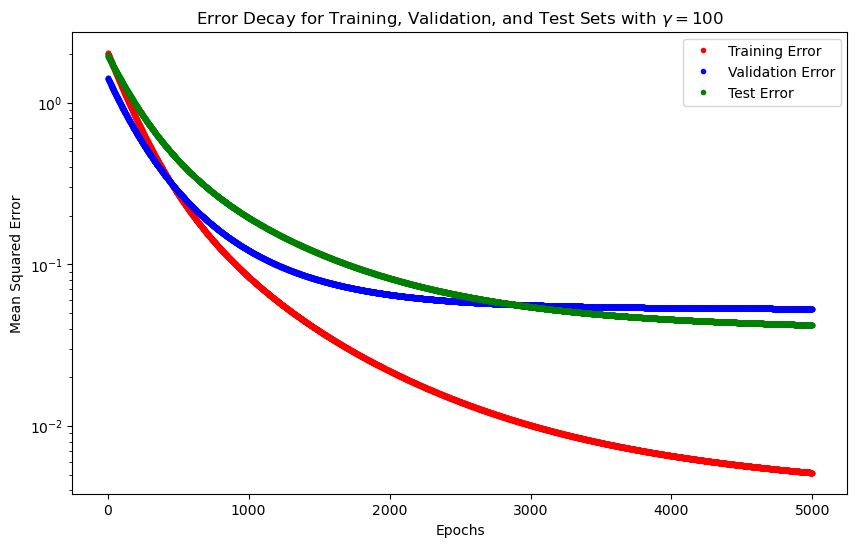

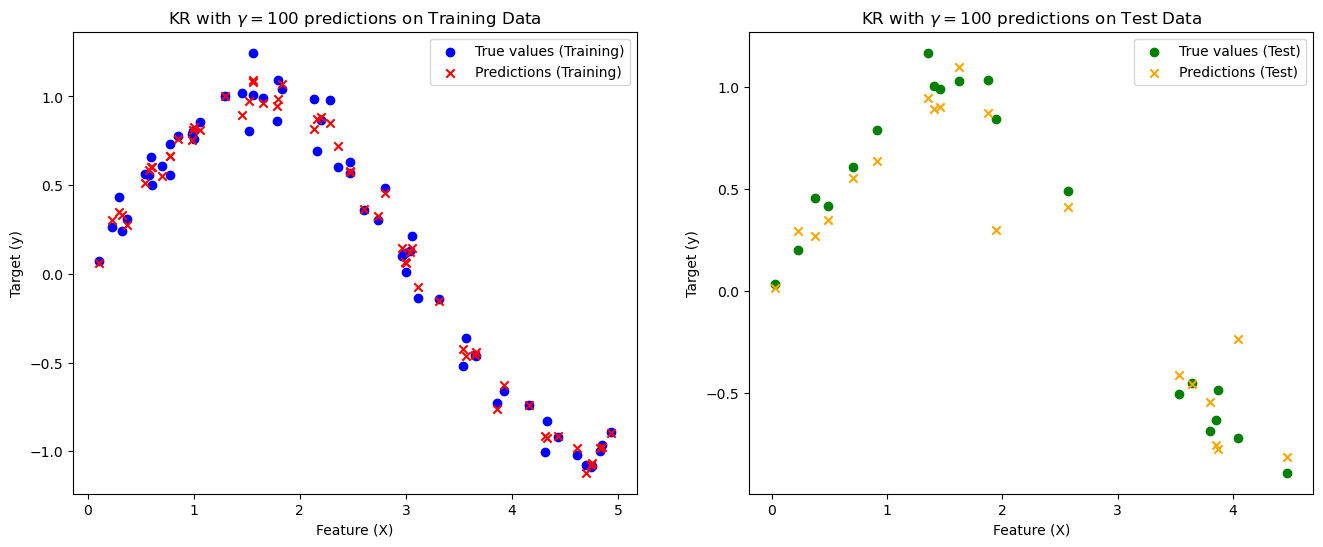

In [6]:
gamma = 100  # Kernel hyperparameter
epochs = 5000
alpha, train_errors, val_errors, test_errors, y_test_pred = train_rbf_kernel(X_train, y_train, X_val, y_val, X_test, y_test, gamma, lr=0.001, epochs=epochs)

# Step 6: Plot error decay over epochs
plt.figure(figsize=(10, 6))
plt.plot(range(epochs), train_errors, 'r.', label="Training Error")
plt.plot(range(epochs), val_errors, 'b.', label="Validation Error")
plt.plot(range(epochs), test_errors, 'g.', label="Test Error")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.yscale('log')
plt.title(r"Error Decay for Training, Validation, and Test Sets with $\gamma=100$")
plt.legend()
plt.show()

K_train = rbf_kernel(X_train, X_train, gamma)
y_train_pred = np.dot(K_train, alpha)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# Plot true values and predictions for training set
ax1.scatter(X_train, y_train, color='blue', label="True values (Training)")
ax1.scatter(X_train, y_train_pred, color='red', label="Predictions (Training)", marker='x')
ax1.set_xlabel("Feature (X)")
ax1.set_ylabel("Target (y)")
ax1.set_title(r"KR with $\gamma=100$ predictions on Training Data")
ax1.legend()

# Plot true values and predictions for test set
ax2.scatter(X_test, y_test, color='green', label="True values (Test)")
ax2.scatter(X_test, y_test_pred, color='orange', label="Predictions (Test)", marker='x')
ax2.set_xlabel("Feature (X)")
ax2.set_ylabel("Target (y)")
ax2.set_title(r"KR with $\gamma=100$ predictions on Test Data")
ax2.legend()
plt.show()

Epoch 0, Training Loss: 15.1339, Validation Loss: 11.0059, Test Loss: 14.5635
Epoch 100, Training Loss: 0.5969, Validation Loss: 0.5127, Test Loss: 0.5202
Epoch 200, Training Loss: 0.0859, Validation Loss: 0.0904, Test Loss: 0.0853
Epoch 300, Training Loss: 0.0277, Validation Loss: 0.0355, Test Loss: 0.0349
Epoch 400, Training Loss: 0.0177, Validation Loss: 0.0238, Test Loss: 0.0242
Epoch 500, Training Loss: 0.0147, Validation Loss: 0.0193, Test Loss: 0.0199
Epoch 600, Training Loss: 0.0132, Validation Loss: 0.0166, Test Loss: 0.0172
Epoch 700, Training Loss: 0.0122, Validation Loss: 0.0148, Test Loss: 0.0152
Epoch 800, Training Loss: 0.0115, Validation Loss: 0.0135, Test Loss: 0.0137
Epoch 900, Training Loss: 0.0110, Validation Loss: 0.0126, Test Loss: 0.0125


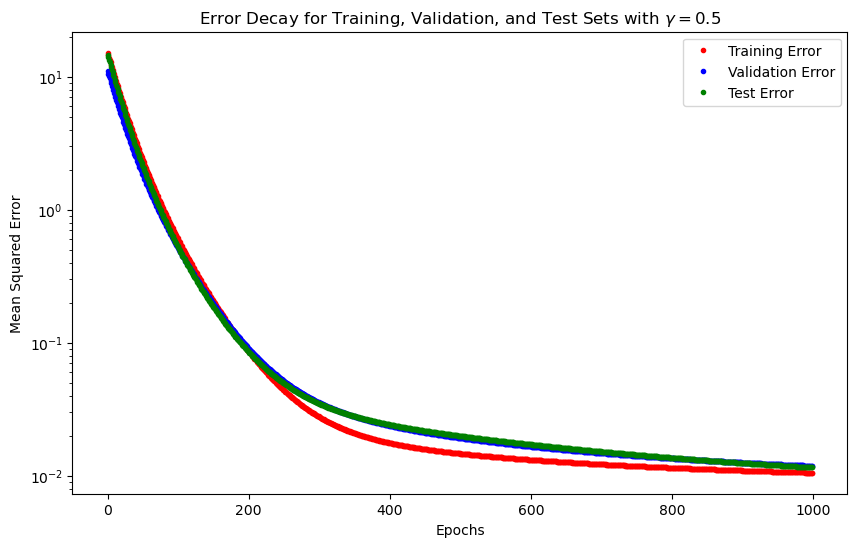

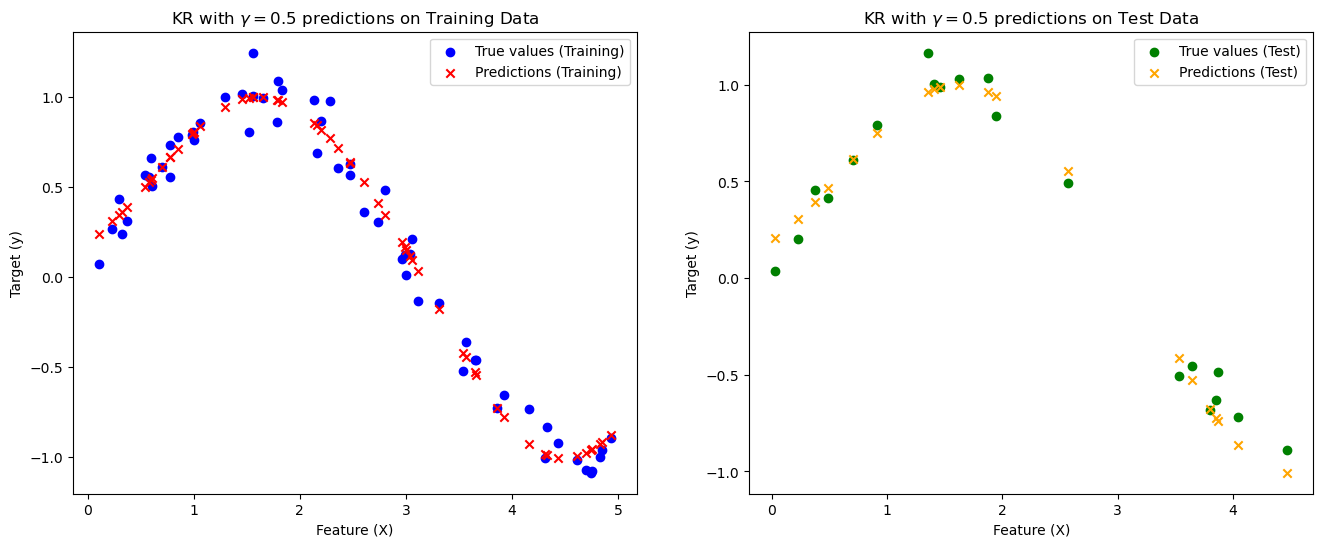

In [7]:
gamma = 0.5  # Kernel hyperparameter
epochs = 1000
alpha, train_errors, val_errors, test_errors, y_test_pred = train_rbf_kernel(X_train, y_train, X_val, y_val, X_test, y_test, gamma, lr=0.001, epochs=epochs)

# Step 6: Plot error decay over epochs
plt.figure(figsize=(10, 6))
plt.plot(range(epochs), train_errors, 'r.', label="Training Error")
plt.plot(range(epochs), val_errors, 'b.', label="Validation Error")
plt.plot(range(epochs), test_errors, 'g.', label="Test Error")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.yscale('log')
plt.title(r"Error Decay for Training, Validation, and Test Sets with $\gamma=0.5$")
plt.legend()
plt.show()

K_train = rbf_kernel(X_train, X_train, gamma)
y_train_pred = np.dot(K_train, alpha)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# Plot true values and predictions for training set
ax1.scatter(X_train, y_train, color='blue', label="True values (Training)")
ax1.scatter(X_train, y_train_pred, color='red', label="Predictions (Training)", marker='x')
ax1.set_xlabel("Feature (X)")
ax1.set_ylabel("Target (y)")
ax1.set_title(r"KR with $\gamma=0.5$ predictions on Training Data")
ax1.legend()

# Plot true values and predictions for test set
ax2.scatter(X_test, y_test, color='green', label="True values (Test)")
ax2.scatter(X_test, y_test_pred, color='orange', label="Predictions (Test)", marker='x')
ax2.set_xlabel("Feature (X)")
ax2.set_ylabel("Target (y)")
ax2.set_title(r"KR with $\gamma=0.5$ predictions on Test Data")
ax2.legend()
plt.show()

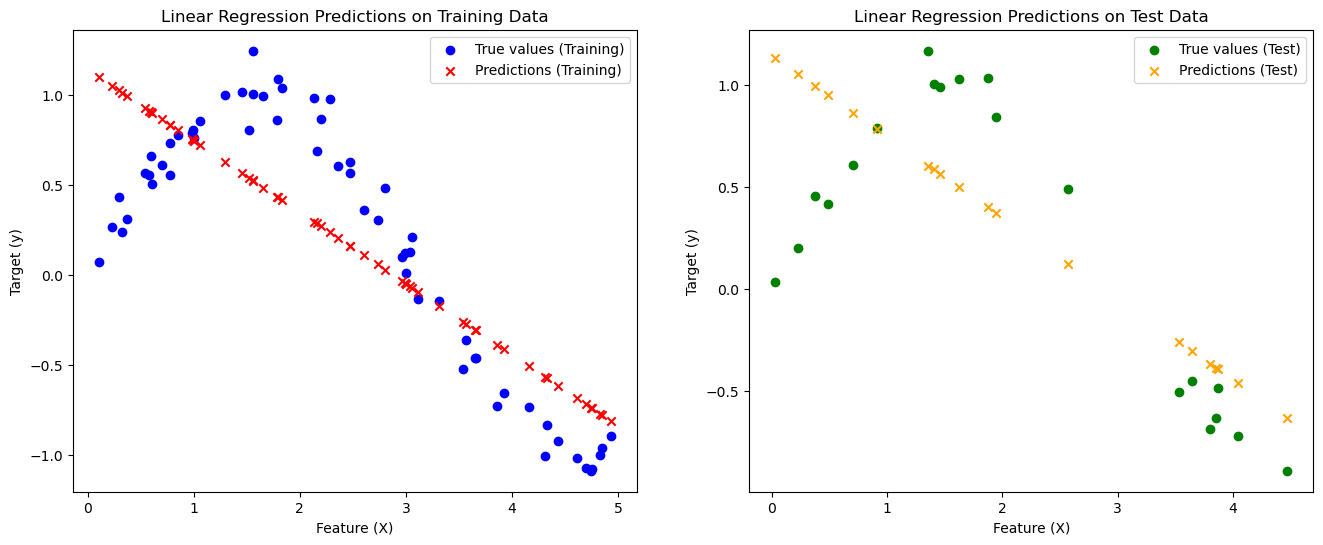

In [23]:
def train_linear_regression(X_train, y_train):
    """Train a linear regression model using the normal equation."""
    # Add a column of ones to X_train to account for the intercept term
    X_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]
    
    # Compute the optimal weights using the normal equation
    theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_train)
    
    return theta

def predict_linear_regression(X, theta):
    """Make predictions using the linear regression model."""
    X_b = np.c_[np.ones((X.shape[0], 1)), X]  # Add bias term
    return X_b.dot(theta)


# Train the Linear Regression model
theta_linear = train_linear_regression(X_train, y_train)

# Make predictions using the Linear Regression model
y_train_pred_linear = predict_linear_regression(X_train, theta_linear)
y_test_pred_linear = predict_linear_regression(X_test, theta_linear)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# Plot true values and predictions for training set
ax1.scatter(X_train, y_train, color='blue', label="True values (Training)")
ax1.scatter(X_train, y_train_pred_linear, color='red', label="Predictions (Training)", marker='x')
ax1.set_xlabel("Feature (X)")
ax1.set_ylabel("Target (y)")
ax1.set_title("Linear Regression Predictions on Training Data")
ax1.legend()

# Plot true values and predictions for test set
ax2.scatter(X_test, y_test, color='green', label="True values (Test)")
ax2.scatter(X_test, y_test_pred_linear, color='orange', label="Predictions (Test)", marker='x')
ax2.set_xlabel("Feature (X)")
ax2.set_ylabel("Target (y)")
ax2.set_title("Linear Regression Predictions on Test Data")
ax2.legend()
plt.show()

Epoch 0, Training Loss: 2.2309, Validation Loss: 1.7362, Test Loss: 1.6115
Epoch 100, Training Loss: 0.3200, Validation Loss: 0.3996, Test Loss: 0.3343
Epoch 200, Training Loss: 0.1588, Validation Loss: 0.2693, Test Loss: 0.2124
Epoch 300, Training Loss: 0.0984, Validation Loss: 0.1864, Test Loss: 0.1407
Epoch 400, Training Loss: 0.0656, Validation Loss: 0.1315, Test Loss: 0.0951
Epoch 500, Training Loss: 0.0462, Validation Loss: 0.0956, Test Loss: 0.0664
Epoch 600, Training Loss: 0.0342, Validation Loss: 0.0719, Test Loss: 0.0479
Epoch 700, Training Loss: 0.0265, Validation Loss: 0.0557, Test Loss: 0.0358
Epoch 800, Training Loss: 0.0213, Validation Loss: 0.0445, Test Loss: 0.0276
Epoch 900, Training Loss: 0.0178, Validation Loss: 0.0365, Test Loss: 0.0220
Fold 1/5: Train Error = 0.0154, Val Error = 0.0308, Test Error = 0.0182
Epoch 0, Training Loss: 16.7950, Validation Loss: 21.9432, Test Loss: 7.6978
Epoch 100, Training Loss: 1.2669, Validation Loss: 1.6339, Test Loss: 0.4449
Epoch 

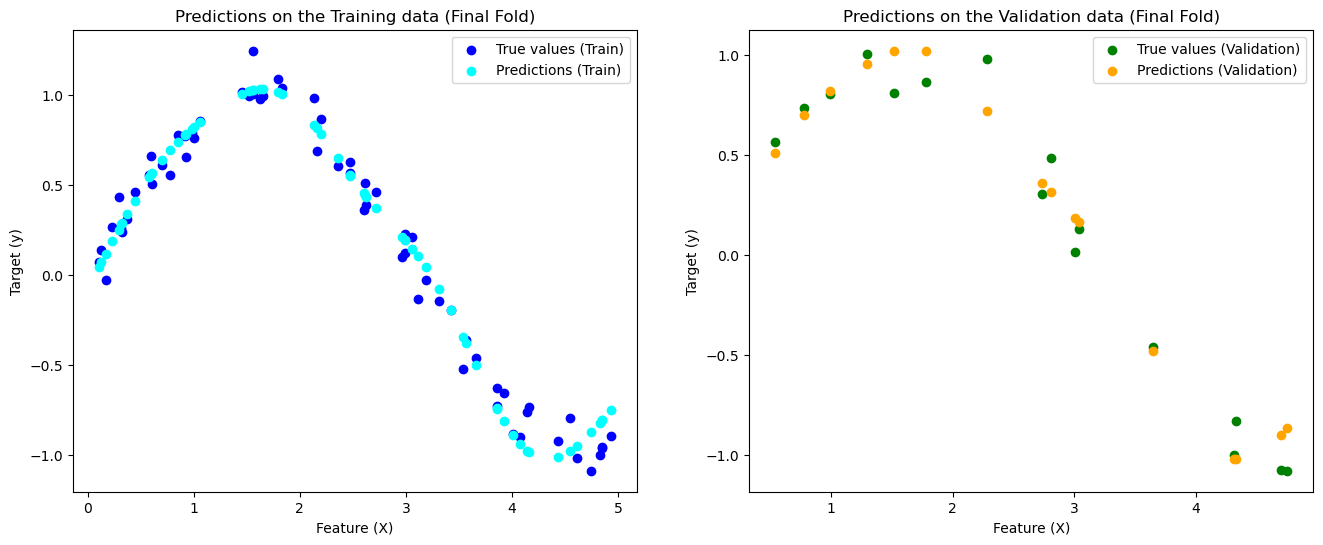

In [47]:

from sklearn.model_selection import KFold

# Cross-validation implementation with separate test set
def cross_validation_rbf_with_test_split(X, y, test_size=0.2, gamma=0.1, lr=0.001, epochs=1000, K=5):
    """Perform K-fold cross-validation on the RBF kernel regression model with test set tracking."""
    
    # Split the data into training/validation and test sets first
    X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=test_size, random_state=42)
    
    # Now apply K-fold cross-validation on the training/validation set
    kf = KFold(n_splits=K, shuffle=True, random_state=42)
    
    train_loss_history = np.zeros((K, epochs))
    val_loss_history = np.zeros((K, epochs))
    test_loss_history = np.zeros((K, epochs))
    
    alpha_final = None
    X_train_final, X_val_final, y_train_final, y_val_final = None, None, None, None
    
    # Loop over each fold
    for fold, (train_index, val_index) in enumerate(kf.split(X_train_val)):
        X_train, X_val = X_train_val[train_index], X_train_val[val_index]
        y_train, y_val = y_train_val[train_index], y_train_val[val_index]
        
        # Train the RBF kernel model on the current fold
        alpha, train_errors, val_errors, test_errors, y_test_pred = train_rbf_kernel(
            X_train, y_train, X_val, y_val, X_test, y_test, gamma=gamma, lr=lr, epochs=epochs
        )
        
        # Store the loss history for each fold
        train_loss_history[fold, :] = train_errors
        val_loss_history[fold, :] = val_errors
        test_loss_history[fold, :] = test_errors
        
        print(f"Fold {fold + 1}/{K}: Train Error = {train_errors[-1]:.4f}, Val Error = {val_errors[-1]:.4f}, Test Error = {test_errors[-1]:.4f}")
        
        # Store information for the last fold
        if fold == K - 1:
            alpha_final = alpha
            X_train_final, X_val_final = X_train, X_val
            y_train_final, y_val_final = y_train, y_val
    
    # Average errors over all folds
    avg_train_error = np.mean(train_loss_history, axis=0)
    avg_val_error = np.mean(val_loss_history, axis=0)
    avg_test_error = np.mean(test_loss_history, axis=0)
    
    return alpha_final, X_train_final, X_val_final, y_train_final, y_val_final,avg_train_error,avg_val_error,avg_test_error

# Perform K-Fold Cross-Validation (RBF Kernel Regression)
K = 5  # Number of folds
gamma = 1  # Kernel hyperparameter
epochs = 1000
test_size = 0.2

alpha_final, X_train_final, X_val_final, y_train_final, y_val_final,avg_train_loss, avg_val_loss, avg_test_loss = cross_validation_rbf_with_test_split(
    X, y, test_size=test_size, gamma=gamma, lr=0.001, epochs=epochs, K=K)

# Visualize predictions on the final fold
# Compute predictions for training and validation data in the final fold
K_train_final = rbf_kernel(X_train_final, X_train_final, gamma)
y_train_pred_final = np.dot(K_train_final, alpha_final)

K_val_final = rbf_kernel(X_val_final, X_train_final, gamma)
y_val_pred_final = np.dot(K_val_final, alpha_final)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot training data and predictions for the final fold
ax1.scatter(X_train_final, y_train_final, color='blue', label="True values (Train)")
ax1.scatter(X_train_final, y_train_pred_final, color='cyan', label="Predictions (Train)")
ax1.set_xlabel("Feature (X)")
ax1.set_ylabel("Target (y)")
ax1.legend()
ax1.set_title('Predictions on the Training data (Final Fold)')

ax2.scatter(X_val_final, y_val_final, color='green', label="True values (Validation)")
ax2.scatter(X_val_final, y_val_pred_final, color='orange', label="Predictions (Validation)")
ax2.set_xlabel("Feature (X)")
ax2.set_ylabel("Target (y)")
ax2.legend()
ax2.set_title('Predictions on the Validation data (Final Fold)')
plt.show()

(1000,)


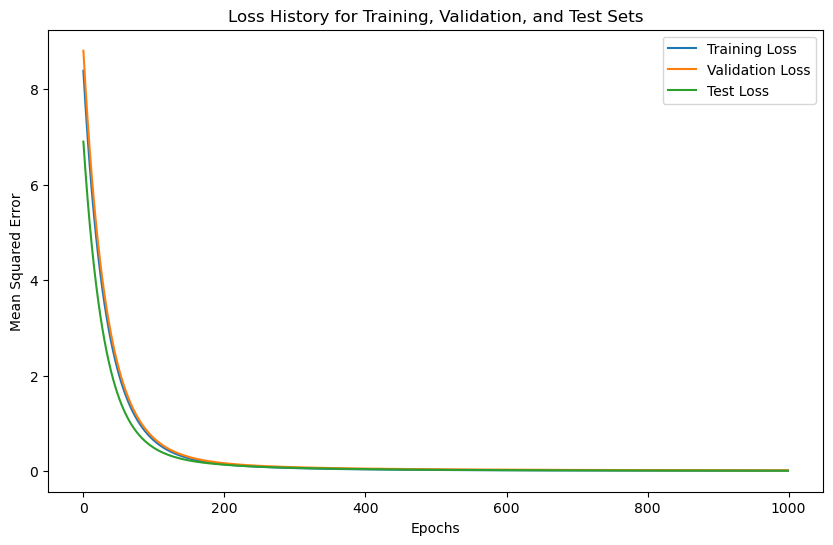

In [48]:
print(avg_train_loss.shape)

# Plot the loss history for training, validation, and test sets
plt.figure(figsize=(10, 6))
plt.plot(range(epochs), avg_train_loss, label="Training Loss")
plt.plot(range(epochs), avg_val_loss, label="Validation Loss")
plt.plot(range(epochs), avg_test_loss, label="Test Loss")

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.title("Loss History for Training, Validation, and Test Sets")
plt.legend()
plt.show()